In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

In [2]:
# Source: wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
df=pd.read_csv('./course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
#data preparation
# replacing missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [5]:
print(df.columns[df.dtypes != 'str']) #numerical features: int and float
numerical_vars=['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'] #target feature (converted) is removed
print('----')
print(df.columns[df.dtypes == 'str']) #categorical features
catergorical_vars = list(df.columns[df.dtypes == 'str'])

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')
----
Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str')


In [6]:
#Fill NaN entries of categorical columns with 'NA'
print(df[catergorical_vars].isnull().sum())
df[catergorical_vars] = df[catergorical_vars].fillna('NA')
print(df[catergorical_vars].isnull().sum())
print(df[catergorical_vars].head())

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64
lead_source          0
industry             0
employment_status    0
location             0
dtype: int64
      lead_source       industry employment_status       location
0  organic_search     technology          employed         europe
1    social_media     technology          employed  south_america
2        referral         retail          employed         europe
3        paid_ads  manufacturing           student             NA
4        referral  manufacturing           student  north_america


In [7]:
#Fill NaN entries of numerical columns with 0.0
print(df[numerical_vars].isnull().sum())
df[numerical_vars] = df[numerical_vars].fillna(0.0)
print(df[numerical_vars].isnull().sum())
print(df[numerical_vars].head())

annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64
   annual_income  number_of_courses_viewed  interaction_count  lead_score
0        88160.0                         3                  4        0.64
1        72688.0                         3                  7        0.72
2        44697.0                         3                  4        0.58
3            0.0                         3                  6        0.57
4        24062.0                         4                  5        0.62


Data spliting

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [9]:
df.shape, df_full_train.shape, df_train.shape, df_val.shape, df_test.shape

((5000, 9), (4000, 9), (3000, 9), (1000, 9), (1000, 9))

In [10]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)
df_full_train=df_full_train.reset_index(drop=True)

y_train=df_train.converted.values
y_val=df_val.converted.values
y_test=df_test.converted.values
y_full_train=df_full_train.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

# Q1

ROC-AUC can also be used to know feature importance of numerical variables. AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

In [11]:
for col in numerical_vars:
    y_score = df_train[col].values
    auc_score = roc_auc_score(y_train, y_score)
    print(col, round(auc_score,3))

#highest AUC score: lead_score    

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


In [12]:
df_train.annual_income.head()

0    80198.0
1    50548.0
2    76300.0
3    80371.0
4    73567.0
Name: annual_income, dtype: float64

# Q2

Training the model

In [13]:
dict_train = df_train[catergorical_vars + numerical_vars].to_dict(orient='records')
dv=DictVectorizer(sparse=False)
X_train = dv.fit_transform(dict_train)
dict_val = df_val[catergorical_vars + numerical_vars].to_dict(orient='records')
X_val = dv.transform(dict_val)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:,1]

In [14]:
round(roc_auc_score(y_val, y_pred),3)

0.732

# Q3

In [34]:
scores = []

thresholds = np.arange(0, 1, 0.01)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

#df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
#df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores.tail()

,threshold,tp,fp,fn,tn,precision,recall
95,0.95,2,0,584,414,1.0,0.003413
96,0.96,1,0,585,414,1.0,0.001706
97,0.97,0,0,586,414,NaN,0.000000
98,0.98,0,0,586,414,NaN,0.000000
99,0.99,0,0,586,414,NaN,0.000000


In [35]:
df_scores.isnull().sum()
df_scores['precision'] = df_scores['precision'].fillna(1)
df_scores.isnull().sum()

threshold    0
tp           0
fp           0
fn           0
tn           0
precision    0
recall       0
dtype: int64

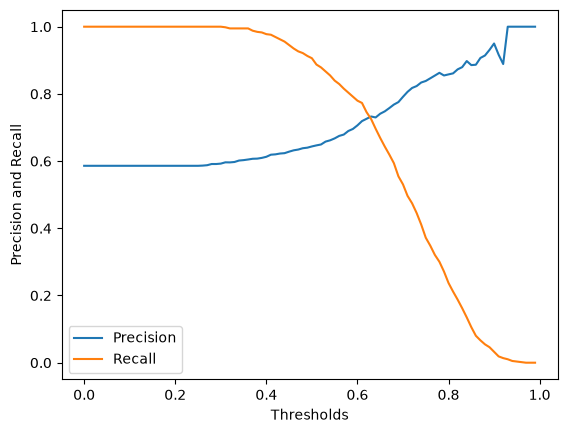

In [36]:
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Thresholds')
plt.ylabel('Precision and Recall')
plt.legend()

In [ ]:
#The point where they meet
df_scores[abs(df_scores.recall - df_scores.precision) == abs(df_scores.recall - df_scores.precision).min()]

,threshold,tp,fp,fn,tn,precision,recall
63,0.63,425,155,161,259,0.732759,0.725256


# Q4

In [50]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)

In [53]:
df_scores.loc[df_scores.f1.idxmax()]

threshold      0.410000
tp           572.000000
fp           352.000000
fn            14.000000
tn            62.000000
precision      0.619048
recall         0.976109
f1             0.757616
Name: 41, dtype: float64

# Q5

In [62]:
def train(df_train, y_train, C=1.0):
    dicts =df_train[catergorical_vars + numerical_vars].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter = 1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[catergorical_vars + numerical_vars].to_dict(orient='records')

    X = dv.transform(dicts) # this is for X_val
    y_pred = model.predict_proba(X)[:,1]
    return y_pred

In [57]:
df_full_train.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [63]:
from sklearn.model_selection import KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [69]:
scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [67]:
round(np.std(scores),3)

np.float64(0.007)

# Q6

In [70]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
